In [1]:
# ---------------------------------------------------------------- parameters
FULL = False     # True: full Table I reproduction (65 devices, 50 epochs, ~45 min on 2 cores)
                 # False: short smoke-test run (20 devices, 20 epochs, ~5 min)
SCALE = 0.6      # size of the figure on the final PowerPoint slide (1.0 = full width)

import json, os, subprocess, sys, time, runpy
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sps
import sim, models, ag

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(0)

# ChaRRNet from first principles

This notebook explains, step by step, a NumPy reproduction of

> C. N. Brown, E. Mattei, A. Draganov, *ChaRRNets: Channel Robust Representation Networks for RF Fingerprinting*, arXiv:2105.03568 (2021).

**The problem.** RF fingerprinting identifies a transmitter from tiny hardware imperfections in its signal. A deep network trained on bursts recorded in one place also learns that place's *multipath channel*, so it fails when the channel changes. ChaRRNet builds the symmetry of the multipath channel into its first layers, so that their output is (ideally) unaffected by the channel.

**What is reproduced.** The simulated experiments: Table I (accuracy across channel models) and Fig. 2 (equivariance/invariance of the layers). The real-world datasets of Tables II–III are not public.

**Code layout** (all plain NumPy/SciPy; no deep-learning framework is needed):

| module | role |
|---|---|
| `sim.py` | 802.11a/g bursts, device fingerprints, multipath channels, datasets |
| `ag.py` | a ~200-line reverse-mode automatic differentiation engine |
| `models.py` | baseline complex CNN and ChaRRNet |
| `train.py`, `fig2.py`, `report.py` | experiments |
| `build_slide.js` | the PowerPoint figure (needs Node.js + `pptxgenjs`) |

Set `FULL` in the first cell to choose between the complete reproduction and a short smoke test.

## 1. The transmitted signal: an 802.11a/g burst

Each burst is a legacy WiFi preamble followed by data: the **short training field** (STF, 10 repetitions of a 16-sample pattern), the **long training field** (LTF, two 64-sample OFDM symbols with a 32-sample cyclic prefix) and four QPSK OFDM data symbols. At 20 Msps that is 640 complex samples. Occupied subcarriers span ±26 × 312.5 kHz ≈ ±8.1 MHz.

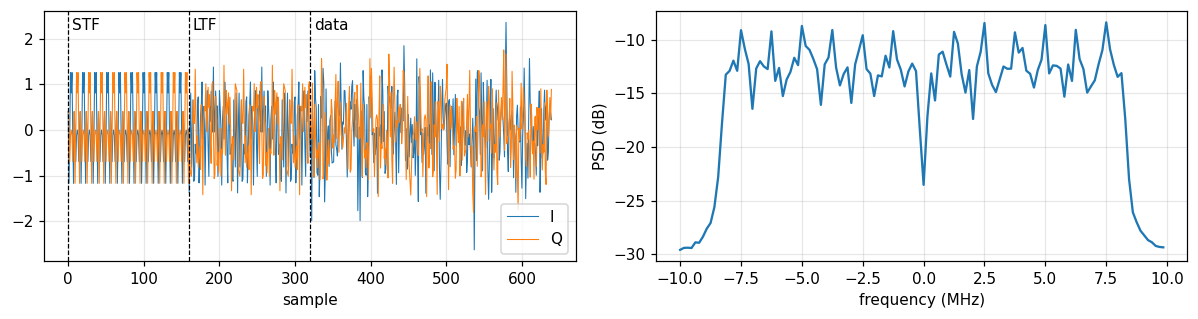

In [2]:
x = sim.wifi_burst(rng)
f, P = sps.welch(x, fs=20, nperseg=128, return_onesided=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(x.real, lw=.7, label='I'); ax[0].plot(x.imag, lw=.7, label='Q')
for b, lab in [(0, 'STF'), (160, 'LTF'), (320, 'data')]:
    ax[0].axvline(b, color='k', ls='--', lw=.8); ax[0].text(b + 5, 2.2, lab)
ax[0].set_xlabel('sample'); ax[0].legend(loc='lower right')
ax[1].plot(np.fft.fftshift(f), 10 * np.log10(np.fft.fftshift(P)))
ax[1].set_xlabel('frequency (MHz)'); ax[1].set_ylabel('PSD (dB)')
plt.tight_layout(); plt.show()

## 2. Device fingerprints, and why they must be *widely linear*

The paper imparts fingerprints with IIR filters, modelling component tolerances in the transmitter's analogue low-pass filters. Here is the subtle point that decides whether ChaRRNet can work at all.

A multipath channel is a complex LTI filter, $r = h_c * x$, so in the frequency domain $R(f) = H_c(f)\,X(f)$. If the device fingerprint were *also* a single complex LTI filter $G(f)$, the received spectrum would be $H_c(f)G(f)X(f)$. Any representation invariant to an arbitrary $H_c(f)$ is then necessarily invariant to $G(f)$ as well, and the fingerprint is erased together with the channel.

Real transmitters filter **I and Q in separate analogue paths** (paper, Sec. II-A). With real filters $h_I \ne h_Q$,

$$y = h_I * \Re x + j\,h_Q * \Im x \;\Longrightarrow\; Y(f) = \mu(f)X(f) + \nu(f)X^*(-f),\qquad \mu = \tfrac{H_I+H_Q}{2},\;\nu = \tfrac{H_I-H_Q}{2}.$$

The *image* term $\nu(f)X^*(-f)$ couples mirror frequencies. It is not a per-frequency multiplication, so it cannot be cancelled by the channel-invariant layers: this IQ-mismatch signature is what ChaRRNet can learn.

In `sim.DevicePopulation`, each device perturbs the pole radii and angles of a 4th-order Butterworth prototype (cut-off 0.85 × Nyquist) by a relative σ = 0.1, independently for I and Q.

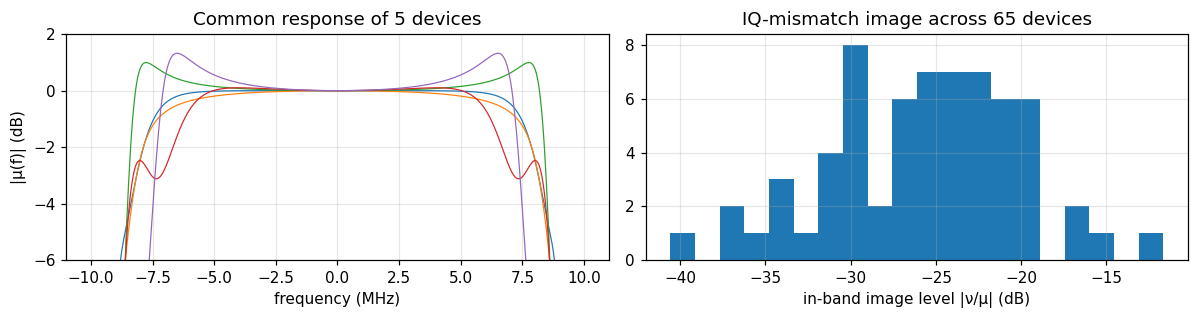

In [3]:
pop = sim.DevicePopulation(65, np.random.default_rng(1), pole_sigma=0.1)
w = np.linspace(-np.pi, np.pi, 512)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
irr = []
for d in range(65):
    (bi, ai), (bq, aq) = pop.filters[d]
    HI = sps.freqz(bi, ai, worN=w)[1]; HQ = sps.freqz(bq, aq, worN=w)[1]
    mu, nu = (HI + HQ) / 2, (HI - HQ) / 2
    band = np.abs(w) < 0.81 * np.pi
    irr.append(np.median(20 * np.log10(np.abs(nu[band] / mu[band]))))
    if d < 5:
        ax[0].plot(w / np.pi * 10, 20 * np.log10(np.abs(mu)), lw=.8)
ax[0].set_xlabel('frequency (MHz)'); ax[0].set_ylabel('|μ(f)| (dB)'); ax[0].set_ylim(-6, 2)
ax[0].set_title('Common response of 5 devices')
ax[1].hist(irr, 20); ax[1].set_xlabel('in-band image level |ν/μ| (dB)')
ax[1].set_title('IQ-mismatch image across 65 devices')
plt.tight_layout(); plt.show()

## 3. The multipath channel

Following Sec. III-A, a channel is drawn from a **reflector geometry**: transmitter and receiver 15 m apart, N reflectors placed uniformly in a box around them. Each path has

* excess delay $\tau_k = (|\mathbf{p}_k| + |\mathbf{p}_k - \mathbf{rx}| - d_\text{LOS})/c$,
* attenuation drawn from U[−15, −5] dB,
* carrier phase $2\pi f_c L_k / c$.

The nominal reflector positions are fixed per configuration (that is the "channel model"), and each burst jitters them by 0.5 m. At 2.4 GHz (λ = 12.5 cm) this randomises the phases completely but barely changes the delays. The taps are band-limited with a windowed sinc, and the channel is normalised to unit energy. "LOS" adds a direct path; with hundreds of reflectors at −10 dB on average it is a small part of the total power, so LOS and nLOS behave alike.

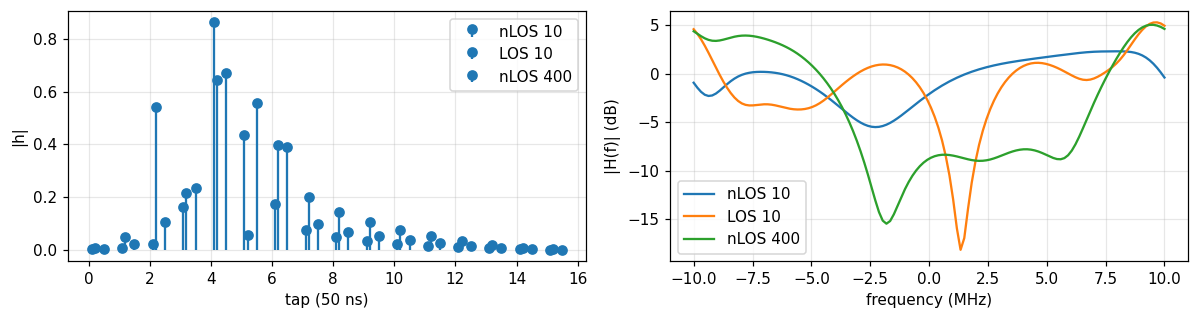

In [4]:
cfgs = sim.channel_configs()
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for name in ['nLOS 10', 'LOS 10', 'nLOS 400']:
    h = cfgs[name].draw(rng)
    ax[0].stem(np.arange(len(h)) + 0.1 * list(cfgs).index(name), np.abs(h), label=name, basefmt=' ')
    ax[1].plot(np.linspace(-10, 10, 128), 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(h, 128)))), label=name)
ax[0].set_xlabel('tap (50 ns)'); ax[0].set_ylabel('|h|'); ax[0].legend()
ax[1].set_xlabel('frequency (MHz)'); ax[1].set_ylabel('|H(f)| (dB)'); ax[1].legend()
plt.tight_layout(); plt.show()

### Dataset generation

`sim.make_dataset` produces, for every device, bursts that pass through: random data → device I/Q filters → (optional) channel draw → random carrier-frequency offset (±40 kHz) and phase → AWGN at SNR ~ U[15, 30] dB → unit-power normalisation. CFO and AWGN are augmentations used for every model, as in the paper.

In [5]:
X, y = sim.make_dataset(pop, 2, cfgs['nLOS 30'], rng)
print('bursts:', X.shape, ' labels:', y[:6], '...')

bursts: (130, 640)  labels: [0 0 1 1 2 2] ...


## 4. From convolution to per-bin multiplication: the STFT

By the convolution theorem, $\mathcal{F}(h_c * x) = H_c \cdot X$. ChaRRNet applies this *locally*: it cuts the burst into overlapping windows (STFT, 128 points, hop 16, giving 33 windows × 128 bins) and treats each frequency bin separately. If each window were convolved with the channel independently, **every window in bin f would be multiplied by the same complex number $H_c(f)$**:

$$S_t(f) \;\longrightarrow\; H_c(f)\,S_t(f)\quad\text{for all windows } t.$$

This is the "ideal action" of the paper. Physically, the channel's impulse response spills across window edges (the first $L-1$ samples of a window contain the previous window's tail), so the identity only holds approximately. Tapering the windows with a **Kaiser window** (β = 8) reduces that boundary effect.

In [6]:
xb = pop.apply(sim.wifi_burst(rng), 0)
h = cfgs['nLOS 30'].draw(rng)
H = np.fft.fftshift(np.fft.fft(h, models.NFFT))
for win in ['rect', 'kaiser']:
    S = models.stft(xb[None], win)[0]
    Sc = models.stft(np.convolve(xb, h)[:len(xb)][None], win)[0]
    err = np.linalg.norm(Sc - S * H) / np.linalg.norm(S * H)
    print(f'{win:6s} window: ||STFT(h*x) - H·STFT(x)|| / ||H·STFT(x)|| = {err:.3f}')

rect   window: ||STFT(h*x) - H·STFT(x)|| / ||H·STFT(x)|| = 0.259
kaiser window: ||STFT(h*x) - H·STFT(x)|| / ||H·STFT(x)|| = 0.151


## 5. The manifold ℝ⁺ × U(1) and the log map

Write each STFT coefficient in polar form, $z = r e^{i\theta}$. The magnitudes form the Lie group $(\mathbb{R}^+, \times)$ and the phases form $U(1)$; the channel acts on them by $r \mapsto |H| r$ and $\theta \mapsto \theta + \angle H$.

The **logarithmic map** takes the group to its Lie algebra (its tangent space at the identity), where the group operation becomes addition:

$$\log(r e^{i\theta}) = (\ln r,\; \theta), \qquad \log(H z) = (\ln r + \ln|H|,\; \theta + \angle H).$$

So in $(\ln r, \theta)$ coordinates **the channel is just a translation**, the same vector for every window of a bin. `models.to_manifold` computes these coordinates.

In [7]:
S = models.stft(xb[None])[0]; f0 = 40
lr, th = np.log(np.abs(S[:, f0])), np.angle(S[:, f0])
lr2, th2 = np.log(np.abs(H[f0] * S[:, f0])), np.angle(H[f0] * S[:, f0])
d = (th2 - th + np.pi) % (2 * np.pi) - np.pi
print('Δ ln r for every window :', np.round(lr2 - lr, 4)[:6], '...  ln|H| =', round(np.log(abs(H[f0])), 4))
print('Δ θ   for every window :', np.round(d, 4)[:6], '...  ∠H    =', round(np.angle(H[f0]), 4))

Δ ln r for every window : [-0.6161 -0.6161 -0.6161 -0.6161 -0.6161 -0.6161] ...  ln|H| = -0.6161
Δ θ   for every window : [2.1034 2.1034 2.1034 2.1034 2.1034 2.1034] ...  ∠H    = 2.1034


## 6. The equivariant layer: weighted Fréchet means

The mean of points on a manifold is the **Fréchet mean**. On this product group it has a closed form: average in the tangent space, then map back.

* magnitude: $\exp\big(\sum_i w_i \ln r_i\big)$, a weighted geometric mean;
* phase: $\operatorname{atan2}\big(\sum_i w_i \sin\theta_i,\; \sum_i w_i\cos\theta_i\big)$, the directional mean.

If every input is translated by $(\ln|H|, \angle H)$ and the weights are **convex** ($w_i \ge 0$, $\sum w_i = 1$, enforced by a softmax), the mean is translated by exactly the same amount. That is **equivariance**: $f(Tx) = T f(x)$.

The layer is a "convolution" whose kernel slides along the *window* axis, separately for each frequency bin, with learned weights: `models.wfm_conv` (kernel 4 windows, stride 2, 8 output channels). Below, the equivariance error under the ideal action is tiny. What remains comes from the small ε added before the logarithm, which only matters in the near-empty guard-band bins.

In [8]:
net = models.ChaRRNet(65, np.random.default_rng(0))
net.weq.data = rng.standard_normal(net.weq.shape).astype(np.float32)
x0 = models.ChaRRNet.prep(xb[None])
x_ideal = np.concatenate(models.to_manifold(models.stft(xb[None]) * H), 1)
lr0, th0 = net.equivariant(x0); lr1, th1 = net.equivariant(x_ideal)
pred_lr = lr0.data + np.log(np.abs(H))[None, None, None, :]
pred_th = th0.data + np.angle(H)[None, None, None, :]
dth = (th1.data - pred_th + np.pi) % (2 * np.pi) - np.pi
err = np.sqrt(np.sum((lr1.data - pred_lr) ** 2 + dth ** 2)) / np.linalg.norm(pred_lr)
print(f'ideal action: relative equivariance error = {err:.4f}')

ideal action: relative equivariance error = 0.0049


## 7. The invariant layer: distances to the mean

Distances on the manifold are measured in the tangent space:

$$d\big(r_1e^{i\theta_1}, r_2e^{i\theta_2}\big) = \sqrt{\ln^2(r_2/r_1) + \big[\theta_2-\theta_1\big]_{2\pi}^2},$$

with the phase difference wrapped to $[-\pi, \pi)$. A translation moves both points by the same vector, so **distances are invariant**: $f(Tx) = f(x)$.

`models.invariant_layer` first computes one learned Fréchet mean $m$ over a block of (8 channels × 4 windows) of the equivariant layer's output, then returns the distance from *every* input in that block to $m$. Because both the inputs and the mean were shifted by the same $H(f)$, the channel cancels. The output is real-valued (96 feature maps × 3 time steps × 128 bins) and is passed to an ordinary real 1D CNN that convolves along frequency.

In [9]:
net.winv.data = rng.standard_normal(net.winv.shape).astype(np.float32)
z0 = net.invariant(x0).data
z_ideal = net.invariant(x_ideal).data
z_phys = net.invariant(models.ChaRRNet.prep(np.convolve(xb, h)[:len(xb)][None])).data
z_dev = net.invariant(models.ChaRRNet.prep(pop.apply(sim.wifi_burst(np.random.default_rng(5)), 1)[None])).data
rel = lambda a: np.linalg.norm(a - z0) / np.linalg.norm(z0)
print(f'relative change, ideal channel   : {rel(z_ideal):.4f}')
print(f'relative change, physical channel: {rel(z_phys):.4f}')

relative change, ideal channel   : 0.0028
relative change, physical channel: 0.2871


## 8. Reproducing Fig. 2

`fig2.py` repeats this over 200 bursts and three channel models, for a rectangular and a Kaiser window. It also measures, for scale, how much the features change when the **transmitter** is swapped (same burst, different device): that is the signal the classifier must preserve. For comparison, the baseline's first complex-convolution layer (after CReLU) is measured the same way.

In [10]:
runpy.run_path('fig2.py', run_name='__main__')
plt.figure(figsize=(11, 4)); plt.imshow(plt.imread('fig2_equivariance.png')); plt.axis('off'); plt.show()

eq_ideal         median=0.0048  p90=0.0126
eq_phys_rect     median=0.5695  p90=0.6189
eq_phys_kaiser   median=0.3014  p90=0.3295
inv_ideal        median=0.0040  p90=0.0106
inv_phys_rect    median=0.3805  p90=0.4604
inv_phys_kaiser  median=0.3018  p90=0.3283
bl_phys          median=1.1836  p90=1.2507
inv_device       median=0.2787  p90=0.3469
bl_device        median=0.4267  p90=0.6769


/var/folders/y_/fx1ytzjx6nq9b2h5jvyb2md40000gn/T/ipykernel_44385/895981731.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.figure(figsize=(11, 4)); plt.imshow(plt.imread('fig2_equivariance.png')); plt.axis('off'); plt.show()


**Reading it.** Under the ideal action both layers are exact (errors of about 10⁻³ come from the ε inside the logarithm). Physical boundary effects raise the error to 30–60%, and the Kaiser window roughly halves the equivariance error, as the paper claims. Still, the ChaRRNet features change about as much under a channel as under a change of device, whereas the baseline's features change ~3× more under a channel than under a change of device. ChaRRNet's invariance is therefore partial in practice, which is why the paper still uses channel augmentation.

## 9. Training without a deep-learning framework: `ag.py`

PyTorch was not available, so `ag.py` implements **reverse-mode automatic differentiation**. Each operation returns a `T` (tensor) that remembers its parents and a closure computing the vector–Jacobian product. `backward()` sorts the graph topologically and applies the chain rule from the loss back to the parameters.

Only a few primitives are needed: arithmetic with broadcasting, `sin`, `cos`, `atan2`, `sqrt`, phase wrapping (identity gradient almost everywhere), `softmax`, 1D convolution via im2col, max-pooling, the strided window-axis weighted sum used by the Fréchet-mean layers (`tconv`), and softmax cross-entropy. Adam does the optimisation.

A finite-difference check confirms every gradient in both models.

In [11]:
runpy.run_path('gradcheck.py', run_name='__main__')

BaselineCNN: max relative gradient error 1.08e-06
ChaRRNet: max relative gradient error 4.76e-05


{'__name__': '__main__',
 '__doc__': 'Finite-difference check of the NumPy autograd through both models (float64).',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'gradcheck.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__(name, g

## 10. The two models

**Baseline** (in the spirit of Mattei et al. 2019, the paper's reference [12]): three **complex** convolutions on raw IQ. A complex kernel $W = W_r + jW_i$ is implemented as a real convolution on stacked $[\Re x; \Im x]$ channels with block weights $\begin{bmatrix}W_r & -W_i\\ W_i & W_r\end{bmatrix}$, followed by CReLU, max-pooling and a dense head.

**ChaRRNet**: Kaiser STFT → log map → equivariant wFM layer → invariant distance layer → real 1D CNN along frequency → dense head.

Both are about 20× smaller than the paper's (5M and 4M parameters), to train on a CPU.

In [12]:
for M in [models.BaselineCNN, models.ChaRRNet]:
    m = M(65, np.random.default_rng(0))
    print(f'{M.__name__:12s} {sum(p.data.size for p in m.params()):>9,d} parameters')

BaselineCNN    188,097 parameters
ChaRRNet       314,049 parameters


## 11. The Table I experiment

Both models are trained twice: on **pristine** bursts (no channel) and on bursts through the **nLOS-200** channel model (the paper's text says nLOS 200; its table header says LOS200). Each is then tested on pristine bursts and on six *other* channel models, none of which appears in training. The checkpoint with the best in-distribution validation accuracy is kept.

* `FULL = True` reproduces the setup of the saved results (65 devices, 100 bursts/device, 50 epochs) and **overwrites** `res_*.json`.
* `FULL = False` runs a smoke test (20 devices, 20 epochs) into `res_short.json`. It is too short to separate the models reliably; it only shows the pipeline running end to end.

Runs are launched as subprocesses so that two can use both CPU cores.

In [13]:
env = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1')
if FULL:
    jobs = [('baseline', 'Pristine', 'res_bl_p.json'), ('baseline', 'nLOS 200', 'res_bl_n.json'),
            ('charrnet', 'Pristine', 'res_charrnet_pristine.json'), ('charrnet', 'nLOS 200', 'res_charrnet_nlos.json')]
    t0 = time.time()
    for i in range(0, 4, 2):                      # two runs at a time
        procs = [subprocess.Popen([sys.executable, 'train.py', '--models', m, '--train_sets', t,
                                   '--epochs', '50', '--out', o], env=env,
                                  stdout=open(f'log_{o[:-5]}.txt', 'w'), stderr=subprocess.STDOUT)
                 for m, t, o in jobs[i:i + 2]]
        for p in procs: p.wait()
        print(f'finished {[j[2] for j in jobs[i:i+2]]} after {(time.time()-t0)/60:.0f} min')
    result_files = [j[2] for j in jobs]
else:
    t0 = time.time()
    subprocess.run([sys.executable, 'train.py', '--devices', '20', '--train_per_dev', '100',
                    '--test_per_dev', '10', '--epochs', '20', '--out', 'res_short.json'], env=env, check=True)
    print(f'short run finished in {(time.time()-t0)/60:.1f} min')
    result_files = ['res_short.json']

data generated in 1s
baseline train=Pristine  ep 0 loss=3.581 val=0.060 (1s)
baseline train=Pristine  ep 1 loss=2.902 val=0.155 (1s)
baseline train=Pristine  ep 2 loss=2.626 val=0.250 (1s)
baseline train=Pristine  ep 3 loss=2.176 val=0.285 (1s)
baseline train=Pristine  ep 4 loss=1.680 val=0.405 (1s)
baseline train=Pristine  ep 5 loss=1.227 val=0.550 (1s)
baseline train=Pristine  ep 6 loss=0.915 val=0.485 (1s)
baseline train=Pristine  ep 7 loss=0.594 val=0.630 (1s)
baseline train=Pristine  ep 8 loss=0.411 val=0.775 (1s)
baseline train=Pristine  ep 9 loss=0.289 val=0.760 (1s)
baseline train=Pristine  ep10 loss=0.209 val=0.810 (1s)
baseline train=Pristine  ep11 loss=0.144 val=0.845 (1s)
baseline train=Pristine  ep12 loss=0.101 val=0.870 (1s)
baseline train=Pristine  ep13 loss=0.068 val=0.900 (1s)
baseline train=Pristine  ep14 loss=0.043 val=0.925 (1s)
baseline train=Pristine  ep15 loss=0.040 val=0.930 (1s)
baseline train=Pristine  ep16 loss=0.038 val=0.930 (1s)
baseline train=Pristine  ep

In [14]:
res = {}
for f in result_files:
    res.update(json.load(open(f))['results'])
tests = ['Pristine', 'nLOS 10', 'LOS 10', 'nLOS 30', 'LOS 100', 'nLOS 400', 'LOS 400']
cols = ['baseline|Pristine', 'baseline|nLOS 200', 'charrnet|Pristine', 'charrnet|nLOS 200']
print(f"{'test set':10s}" + ''.join(f'{c:>20s}' for c in cols))
for t in tests:
    print(f'{t:10s}' + ''.join(f"{100 * res[c]['test'][t]:20.1f}" for c in cols))
print(f"{'mean MP':10s}" + ''.join(f"{np.mean([100 * res[c]['test'][t] for t in tests[1:]]):20.1f}" for c in cols))

test set     baseline|Pristine   baseline|nLOS 200   charrnet|Pristine   charrnet|nLOS 200
Pristine                  92.5                26.5                31.0                28.5
nLOS 10                   21.5                30.0                27.0                29.0
LOS 10                    16.5                26.5                21.0                28.5
nLOS 30                   20.0                26.0                27.0                27.0
LOS 100                   20.5                24.5                21.0                20.5
nLOS 400                  17.0                30.0                27.0                30.0
LOS 400                   18.5                25.5                25.0                26.0
mean MP                   19.0                27.1                24.7                26.8


**Expected (full run, saved results):** pristine-trained, the baseline collapses to ~10% on every multipath set while ChaRRNet keeps ~35%. Trained with nLOS-200, ChaRRNet beats the baseline on every unseen channel model (66% vs 49% on average). The paper reports the same pattern (25% vs 10%, and 84% vs 77%) with larger models.

The comparison figure below always uses the full results files (`res_bl_*.json`, `res_charrnet_*.json`).

In [15]:
runpy.run_path('report.py', run_name='__main__')
plt.figure(figsize=(12, 4.6)); plt.imshow(plt.imread('table1_comparison.png')); plt.axis('off'); plt.show()

| Test set | Baseline / Pristine | Baseline / nLOS200 | ChaRRNet / Pristine | ChaRRNet / nLOS200 |
|---|---|---|---|---|
| Pristine | **98.8** (80.4) | **34.3** (23.5) | **79.1** (85.5) | **58.2** (24.1) |
| nLOS 10 | **10.2** (11.7) | **51.2** (76.7) | **35.2** (20.9) | **68.8** (83.9) |
| LOS 10 | **8.8** (5.5) | **47.8** (76.5) | **35.6** (23.6) | **65.4** (84.0) |
| nLOS 30 | **8.9** (11.8) | **49.2** (78.4) | **35.2** (26.8) | **67.4** (84.5) |
| LOS 100 | **10.5** (5.4) | **48.0** (70.5) | **36.9** (25.6) | **64.9** (83.0) |
| nLOS 400 | **11.5** (10.8) | **49.5** (78.6) | **34.3** (25.4) | **65.1** (85.1) |
| LOS 400 | **8.1** (11.5) | **46.8** (79.3) | **34.7** (25.4) | **66.2** (85.3) |
| *Mean of 6 multipath sets* | **9.7** (9.5) | **48.7** (76.7) | **35.3** (24.6) | **66.3** (84.3) |
| *Trainable params* | 188,097 | 188,097 | 314,049 | 314,049 |


/var/folders/y_/fx1ytzjx6nq9b2h5jvyb2md40000gn/T/ipykernel_44385/3406947995.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.figure(figsize=(12, 4.6)); plt.imshow(plt.imread('table1_comparison.png')); plt.axis('off'); plt.show()


## 12. One-figure overview (matplotlib)

`fig_overview.py` combines the pipeline, the per-bin channel picture, the log-polar translation and the main result.

In [16]:
runpy.run_path('fig_overview.py', run_name='__main__')
plt.figure(figsize=(13, 7.2)); plt.imshow(plt.imread('charrnet_overview.png')); plt.axis('off'); plt.show()

/var/folders/y_/fx1ytzjx6nq9b2h5jvyb2md40000gn/T/ipykernel_44385/4225235453.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.figure(figsize=(13, 7.2)); plt.imshow(plt.imread('charrnet_overview.png')); plt.axis('off'); plt.show()


## 13. The PowerPoint slide

`export_slide_data.py` writes the numbers behind the figure (`slide_data.json`) and the spectrogram image. `build_slide.js` then draws the slide from native PowerPoint shapes with `pptxgenjs`, scaled by `SCALE`, and `apply_theme.js` writes the colour theme. This needs Node.js with `pptxgenjs` installed (`npm install pptxgenjs`).

In [17]:
runpy.run_path('export_slide_data.py', run_name='__main__')
out = subprocess.run(['node', 'build_slide.js'], env=dict(os.environ, SCALE=str(SCALE)),
                     capture_output=True, text=True)
print(out.stdout or out.stderr)
print('slide written to', os.path.abspath('charrnet_overview.pptx'))

node:internal/modules/cjs/loader:1573
  throw err;
  ^

Error: Cannot find module 'pptxgenjs'
Require stack:
- /Users/phwl/repo/phwl-research/doodle/notebooks/charrnet/build_slide.js
    at Module._resolveFilename (node:internal/modules/cjs/loader:1569:15)
    at wrapResolveFilename (node:internal/modules/cjs/loader:1123:27)
    at defaultResolveImplForCJSLoading (node:internal/modules/cjs/loader:1147:10)
    at resolveForCJSWithHooks (node:internal/modules/cjs/loader:1174:12)
    at Module._load (node:internal/modules/cjs/loader:1346:5)
    at wrapModuleLoad (node:internal/modules/cjs/loader:261:19)
    at Module.require (node:internal/modules/cjs/loader:1679:12)
    at require (node:internal/modules/helpers:196:16)
    at Object.<anonymous> (/Users/phwl/repo/phwl-research/doodle/notebooks/charrnet/build_slide.js:2:17)
    at Module._compile (node:internal/modules/cjs/loader:1934:14) {
  code: 'MODULE_NOT_FOUND',
  requireStack: [
    '/Users/phwl/repo/phwl-research/doodle/notebooks/c